## 300m indicator - stats & vizualization for bologna

In [25]:
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import math 
import os
import sqlite3
from shapely.strtree import STRtree

TEAL  = "#1D9E75"
BLUE  = "#378ADD"
CORAL = "#F0997B"
LGRAY = "#D3D1C7"
AMBER = "#EF9F27"
TEXT  = "#2C2C2A"
SGRAY = "#888780"

plt.rcParams.update({
    "font.family":        "sans-serif",
    "font.size":          11,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.linewidth":     0.6,
    "xtick.major.size":   3,
    "ytick.major.size":   3,
    "figure.dpi":         150,
    "savefig.bbox":       "tight",
    "savefig.dpi":        150,
})


In [116]:
os.chdir("/Users/terezasaskova/Library/Mobile Documents/com~apple~CloudDocs/3-30-300-index")

CRS_METRIC = 'EPSG:32632'

buildings_routed = gpd.read_file('data/300m/300_walkability_map.gpkg', driver='GPKG', layer='buildings')
parks = gpd.read_file('data/300m/300_walkability_map.gpkg', driver='GPKG', layer='parks')
results = pd.read_csv("data/300m/buildings_300m_indicator.csv")
parks_full = pd.concat([
    gpd.read_file('data/300m/bologna_greenery.gpkg', layer=l)
    for l in ['pe_unis_all', 'osm_public']
], ignore_index=True)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver GPKG does not support open option DRIVER
  return ogr_read(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver GPKG does not support open option DRIVER
  return ogr_read(


In [117]:
# ── Compute park_area_ha and derived compliance columns ──────────────────────
# park_area_ha is no longer stored in the greenery source; compute it here
# from the parks GeoDataFrame geometry (already in CRS_METRIC = metres).

park_area = (
    parks[["park_id", "geometry"]]
    .copy()
    .to_crs(CRS_METRIC)
    .assign(park_area_ha=lambda df: df.geometry.area / 10_000)
    [["park_id", "park_area_ha"]]
)

# Join onto results via nearest_park_id
results = results.merge(
    park_area.rename(columns={"park_id": "nearest_park_id"}),
    on="nearest_park_id",
    how="left",
)

# Derive compliance columns used downstream
results["compliant_0ha"]   = results["within_300m"]
results["compliant_0.5ha"] = results["within_300m"] & (results["park_area_ha"] >= 0.5)
results["compliant_1.0ha"] = results["within_300m"] & (results["park_area_ha"] >= 1.0)

print(f"park_area_ha added — range: "
      f"{results['park_area_ha'].min():.2f} – {results['park_area_ha'].max():.2f} ha")
print(results[["park_area_ha", "compliant_0ha", "compliant_0.5ha", "compliant_1.0ha"]].describe().round(3))


park_area_ha added — range: 0.00 – 45.60 ha
       park_area_ha
count     61399.000
mean          1.348
std           3.333
min           0.000
25%           0.048
50%           0.209
75%           1.236
max          45.597


## Stats from walkability computation mapping in Bologna

In [29]:
total    = len(results)
avg = results['walk_dist_m'].mean()
within   = results['within_300m'].sum()
no_park  = results['nearest_park_id'].isna().sum()
routed   = results['nearest_park_id'].notna().sum()
outside  = routed - within        

print('300m PARK ACCESS INDICATOR — BOLOGNA')
print(f'STREET NUMBERS:')
print(f'Total civici:                  {total:>8,}')
print(f'Within 300m walk of park:      {within:>8,}  ({within/total*100:.1f}%)')
print(f'Outside 300m (park too far):   {outside:>8,}  ({outside/total*100:.1f}%)')
print(f'No park reachable (NaN):       {no_park:>8,}  ({no_park/total*100:.1f}%)')

print(f'\nWALK DISTANCE (routed buildings only):')
reachable = results[results['nearest_park_id'].notna()]
print(f'Median walk distance:          {results["walk_dist_m"].median():>8.0f} m')
print(f'Mean walk distance:            {results["walk_dist_m"].mean():>8.0f} m')
print(f'Max walk distance:             {results["walk_dist_m"].max():>8.0f} m')

print(f'\nPARKS REACHED:')
print(f'Unique parks accessed:         {results["nearest_park_id"].nunique():>8,}')


300m PARK ACCESS INDICATOR — BOLOGNA
STREET NUMBERS:
Total civici:                    77,630
Within 300m walk of park:        59,266  (76.3%)
Outside 300m (park too far):      2,133  (2.7%)
No park reachable (NaN):         16,231  (20.9%)

WALK DISTANCE (routed buildings only):
Median walk distance:               130 m
Mean walk distance:                 141 m
Max walk distance:                 3184 m

PARKS REACHED:
Unique parks accessed:            1,158


## By neighbourhood

In [30]:
print('BY NEIGHBOURHOOD:')
neigh = (results.groupby('neighbourhood')
           .agg(
               total        = ('within_300m', 'count'),
               within_300m  = ('within_300m', 'sum'),
               median_dist  = ('walk_dist_m', 'median'),
           )
           .assign(pct_within = lambda x: x['within_300m'] / x['total'] * 100)
           .sort_values('pct_within')
)
print(neigh.to_string())

print('\nWORST 5 NEIGHBOURHOODS (by % within 300m):')
print(neigh.head())

print('\nBEST 5 NEIGHBOURHOODS:')
print(neigh.tail())

# Flag the routing outliers
print(f'\nBuildings with walk_dist > 1000m: {(results["walk_dist_m"] > 1000).sum()}')
print(f'Buildings with walk_dist > 2000m: {(results["walk_dist_m"] > 2000).sum()}')

BY NEIGHBOURHOOD:
                         total  within_300m  median_dist  pct_within
neighbourhood                                                       
Santo Stefano            16320        12105     154.2510   74.172794
Navile                   13232        10035     126.7375   75.838875
Porto - Saragozza        17302        13176     145.7330   76.153046
Borgo Panigale - Reno    10669         8275     103.6100   77.561158
San Donato - San Vitale  12629         9831     108.6160   77.844643
Savena                    7478         5844     133.8305   78.149238

WORST 5 NEIGHBOURHOODS (by % within 300m):
                         total  within_300m  median_dist  pct_within
neighbourhood                                                       
Santo Stefano            16320        12105     154.2510   74.172794
Navile                   13232        10035     126.7375   75.838875
Porto - Saragozza        17302        13176     145.7330   76.153046
Borgo Panigale - Reno    10669         82

In [31]:
# Euclidean distance 
# Available for every row that has a matched entrance (within_300m == True).
# For fig3 we need it for all addresses; for rows without an entrance we use
# the nearest-park centroid approach — but here we only have the entrance
# coords, so we restrict the euclid comparison to matched rows only.

def haversine_m(lat1, lon1, lat2, lon2):
    R = 6_371_000
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlam = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlam / 2) ** 2
    return R * 2 * np.arcsin(np.sqrt(a))

matched = results[results["within_300m"] & results["entrance_lat"].notna()].copy()
matched["euclid_dist_m"] = haversine_m(
    matched["latitude"].values,  matched["longitude"].values,
    matched["entrance_lat"].values, matched["entrance_lon"].values,
)
matched["ratio"] = matched["walk_dist_m"] / matched["euclid_dist_m"]

## Neighbourhood compliance with 300m walk to park rule

In [32]:
total   = len(results)
avg     = results["within_300m"].mean() * 100   # ← was using walk_dist mean, should be % within
within  = results["within_300m"].sum()
no_park = results["nearest_park_id"].isna().sum()
routed  = results["nearest_park_id"].notna().sum()
outside = routed - within

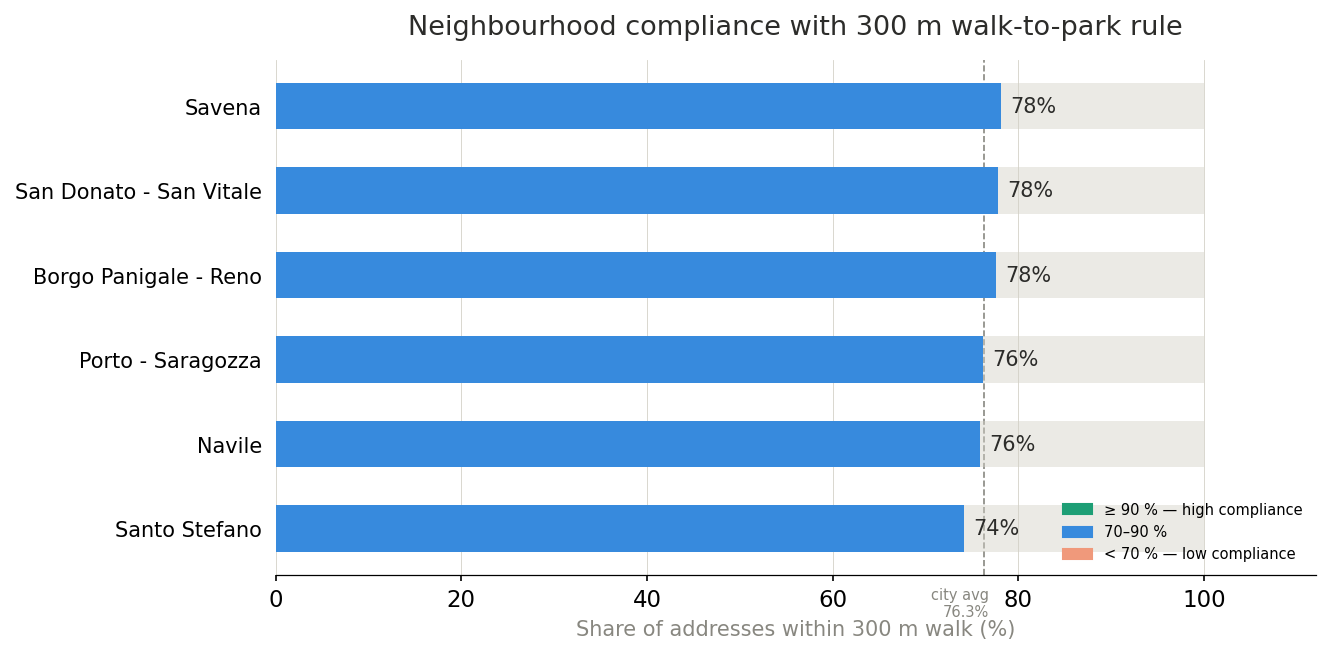

In [33]:


nb = (
    results.groupby("neighbourhood")["within_300m"]
    .agg(total="count", within="sum")
    .assign(pct=lambda x: x["within"] / x["total"] * 100)
    .sort_values("pct", ascending=True)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, max(4.5, len(nb) * 0.55)))
y     = np.arange(len(nb))
BAR_H = 0.55

colors = [TEAL if p >= 90 else BLUE if p >= 70 else CORAL for p in nb.pct]

ax.barh(y, nb.pct,       height=BAR_H, color=colors,       zorder=2)
ax.barh(y, 100 - nb.pct, height=BAR_H, left=nb.pct,
        color=LGRAY, alpha=0.45, zorder=2)

# percentage labels + checkmark — both inside the loop, correct indentation
for i, row in nb.iterrows():
    ax.text(row.pct + 1, i, f"{row.pct:.0f}%",
            va="center", fontsize=10, color=TEXT)
    if row.pct >= 99.5:
        ax.text(row.pct - 2, i, "✓",
                va="center", ha="right", fontsize=11,
                color="white", fontweight="bold")

ax.set_yticks(y)
ax.set_yticklabels(nb.neighbourhood, fontsize=10)
ax.set_xlabel("Share of addresses within 300 m walk (%)",
              fontsize=10, color=SGRAY)
ax.set_xlim(0, 112)   # single xlim — 112 gives room for the % labels

ax.set_title(
    "Neighbourhood compliance with 300 m walk-to-park rule",
    fontsize=13, fontweight="500", pad=12, color=TEXT,
)

# city average line + label at the bottom of the line
ax.axvline(avg, color=SGRAY, linewidth=0.8, linestyle="--", zorder=1)
ax.text(avg + 0.5, -0.7,
        f"city avg\n{avg:.1f}%",
        fontsize=7, color=SGRAY, va="top", ha="right")

ax.grid(axis="x", linewidth=0.4, color=LGRAY, zorder=0)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(left=False)

legend_els = [
    mpatches.Patch(color=TEAL,  label="≥ 90 % — high compliance"),
    mpatches.Patch(color=BLUE,  label="70–90 %"),
    mpatches.Patch(color=CORAL, label="< 70 % — low compliance"),
]
ax.legend(
    handles=legend_els,
    loc="lower right",    # ← inside the axes, no bbox_to_anchor clipping
    fontsize=7,
    frameon=False,
)

plt.tight_layout()
plt.savefig("fig/fig01_neighborhood_walkability_compliance.png",
            dpi=150, bbox_inches="tight")
plt.show()

In [34]:
print(results.columns.tolist())

['street_number', 'address', 'longitude', 'latitude', 'neighbourhood', 'nearest_park_id', 'entrance_lat', 'entrance_lon', 'walk_dist_m', 'within_300m', 'park_area_ha', 'compliant_0ha', 'compliant_0.5ha', 'compliant_1.0ha']


## Per-neighbourhood breakdown at key size of park thresholds

In [35]:
nb_detail = (
    results.groupby("neighbourhood")
    .agg(
        total      = ("within_300m", "count"),
        compliant  = ("compliant_0ha",   "sum"),
        comp_05ha  = ("compliant_0.5ha", "sum"),
    )
    .assign(
        compliance_pct = lambda x: x.compliant  / x.total * 100,
        base_pct       = lambda x: x.compliant  / x.total * 100,
        pct_05ha       = lambda x: x.comp_05ha  / x.total * 100,
    )
    .sort_values("compliance_pct", ascending=False)
)

print(nb_detail.round(1).to_string())


                         total  compliant  comp_05ha  compliance_pct  base_pct  pct_05ha
neighbourhood                                                                           
Savena                    7478       5844       2832            78.1      78.1      37.9
San Donato - San Vitale  12629       9831       2932            77.8      77.8      23.2
Borgo Panigale - Reno    10669       8275       3146            77.6      77.6      29.5
Porto - Saragozza        17302      13176       3870            76.2      76.2      22.4
Navile                   13232      10035       4642            75.8      75.8      35.1
Santo Stefano            16320      12105       3302            74.2      74.2      20.2


In [36]:
bologna_nb = ox.geocode_to_gdf("Bologna, Italy")  # city boundary

#bologna - quartieri 
quartieri = ox.features_from_place("Bologna, Italy", tags={"admin_level": "10"})
quartieri = quartieri[quartieri.geometry.geom_type.isin(["Polygon", "MultiPolygon"])]
quartieri = quartieri[["name", "geometry"]].reset_index(drop=True)
print(quartieri["name"].tolist())  

['Borgo Panigale-Reno', 'Quartiere Navile', 'San Donato-San Vitale', 'Santo Stefano', 'Porto-Saragozza', 'Savena', 'Ufficio Scuola - Quartiere Navile']


## Park access by neighbourhood: effect of size filter

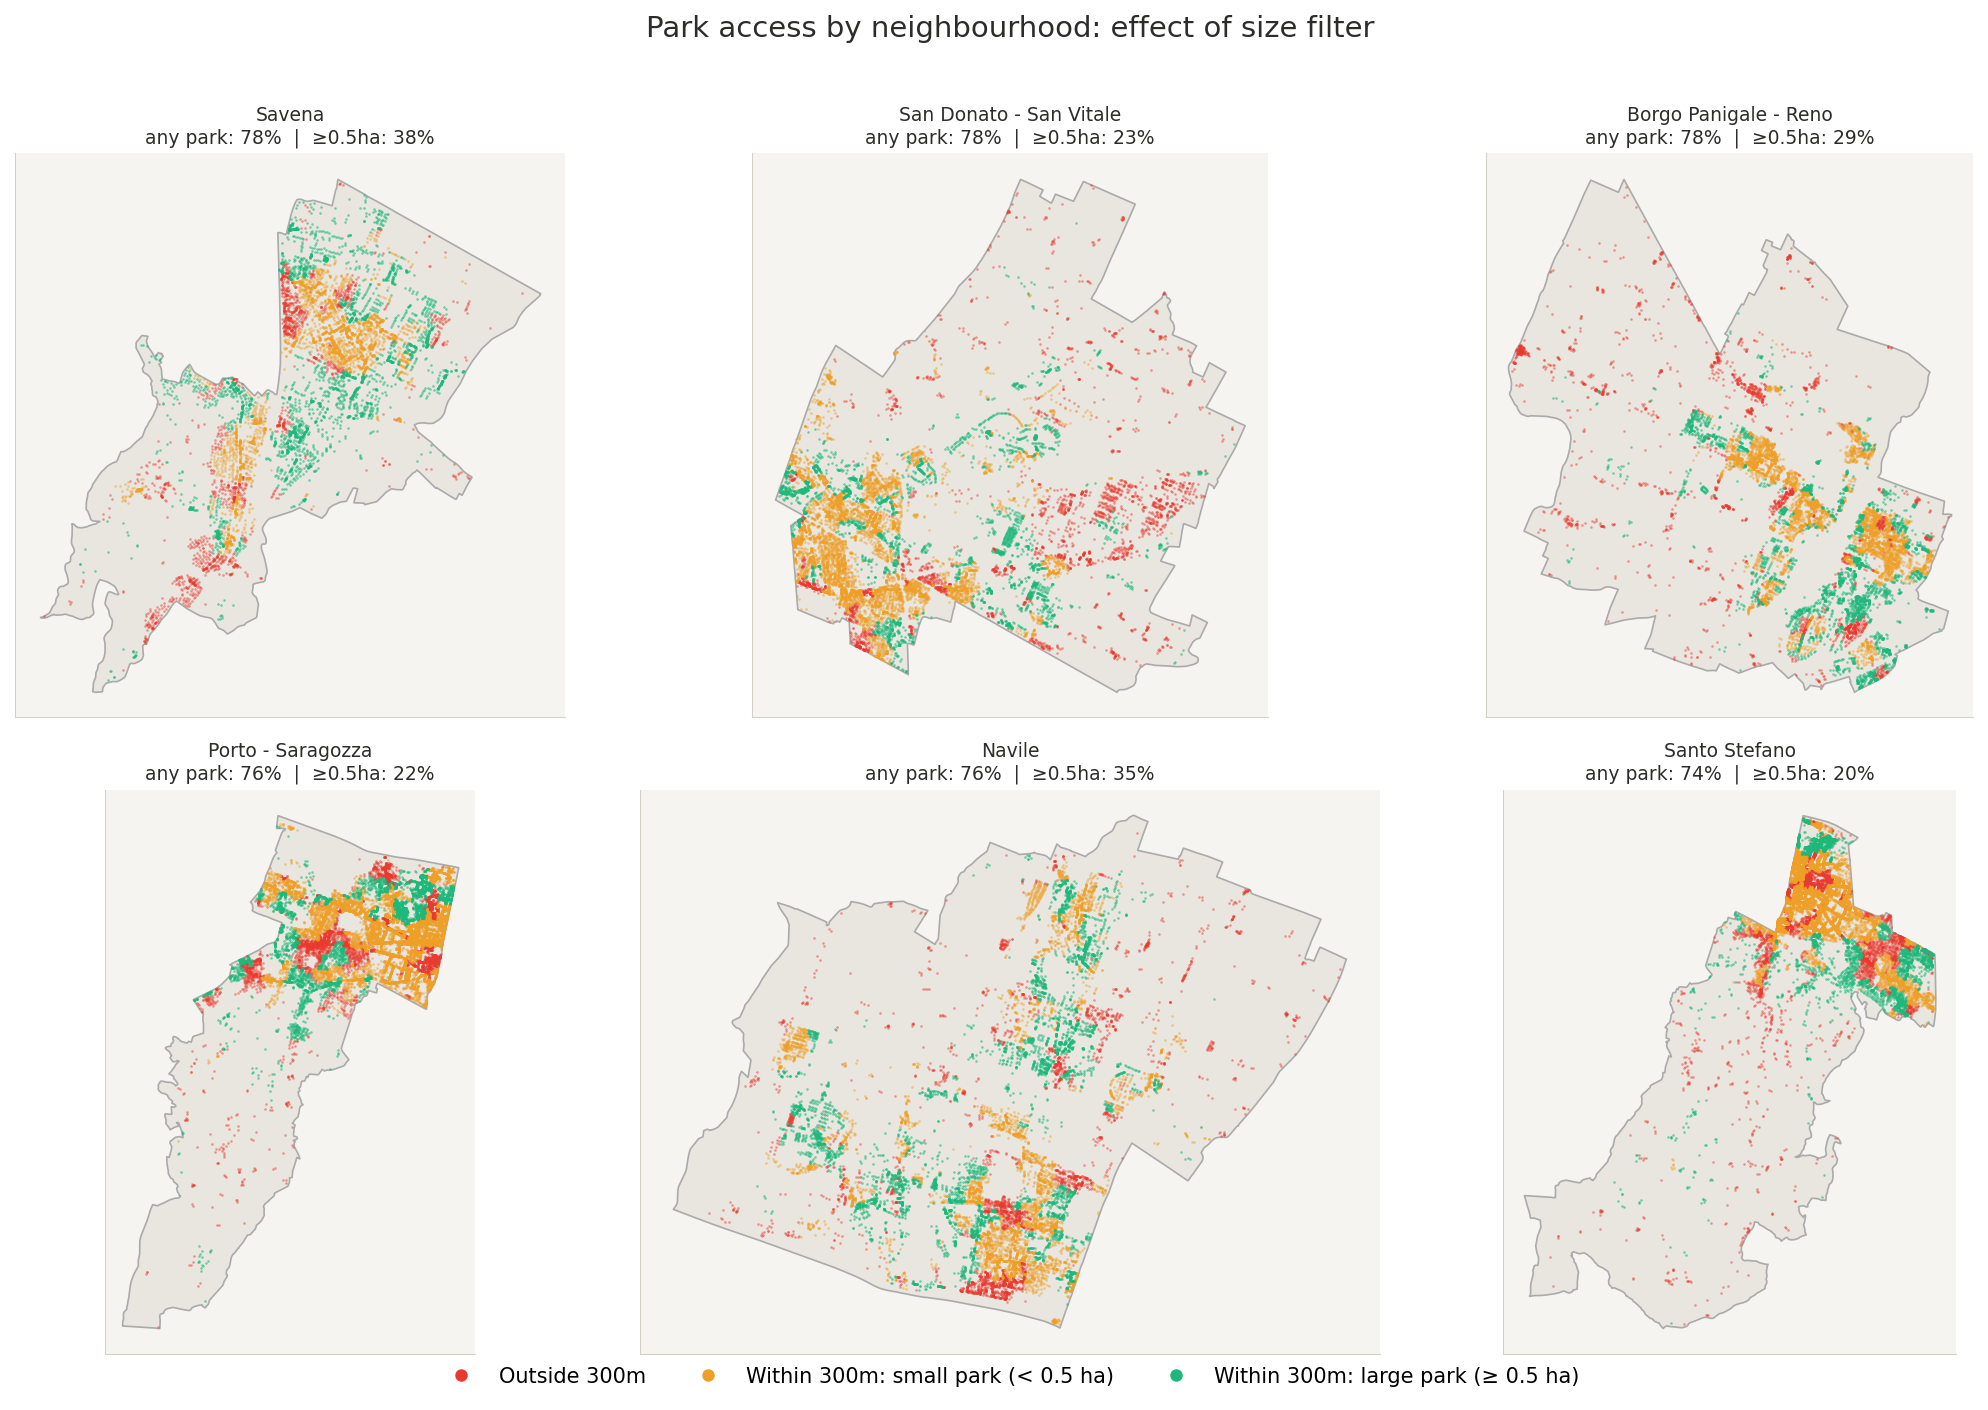

In [90]:
neighbourhoods = nb_detail.index.tolist()  # already sorted by base_pct
n_cols = 3
n_rows = math.ceil(len(neighbourhoods) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4.5))
axes = axes.flatten()

for i, nb in enumerate(neighbourhoods):
    ax = axes[i]
    nb_df = results[results["neighbourhood"] == nb]
    
    inside  = nb_df[nb_df["within_300m"]]
    outside = nb_df[~nb_df["within_300m"]]
    
    # large parks only (≥ 0.5 ha) — highlight separately
    inside_large = nb_df[nb_df["within_300m"] & (nb_df["park_area_ha"] >= 0.5)]
    inside_small = nb_df[nb_df["within_300m"] & (nb_df["park_area_ha"] <  0.5)]
    
    nb_geom = quartieri[quartieri["name"].str.contains(nb.split(" - ")[0], case=False)]
    if not nb_geom.empty:
        nb_geom.plot(ax=ax, facecolor="#E8E6DF", edgecolor="#AAAAAA",
                     linewidth=0.8, zorder=1)
    
    ax.set_facecolor("#F5F4F0")
 
    
    ax.scatter(outside["longitude"],     outside["latitude"],
        s=1.5, color="#E83A2F", alpha=0.5, linewidths=0, zorder=2, rasterized=True)
    ax.scatter(inside_small["longitude"], inside_small["latitude"],
        s=1.5, color=AMBER,     alpha=0.5, linewidths=0, zorder=3, rasterized=True)
    ax.scatter(inside_large["longitude"], inside_large["latitude"],
        s=1.5, color="#1DB87A", alpha=0.6, linewidths=0, zorder=4, rasterized=True)

    row = nb_detail.loc[nb]
    ax.set_title(
        f"{nb}\n"
        f"any park: {row.base_pct:.0f}%  |  ≥0.5ha: {row.pct_05ha:.0f}%",
        fontsize=9, color=TEXT, pad=5
    )
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor(LGRAY)
        spine.set_linewidth(0.5)

# hide unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

# shared legend
from matplotlib.lines import Line2D
legend_els = [
    Line2D([0],[0], marker='o', color='w', markerfacecolor="#E83A2F", markersize=7, label="Outside 300m"),
    Line2D([0],[0], marker='o', color='w', markerfacecolor=AMBER,     markersize=7, label="Within 300m: small park (< 0.5 ha)"),
    Line2D([0],[0], marker='o', color='w', markerfacecolor="#1DB87A", markersize=7, label="Within 300m: large park (≥ 0.5 ha)"),
]
fig.legend(handles=legend_els, loc="lower center", ncol=3,
    fontsize=10, frameon=False, bbox_to_anchor=(0.5, -0.02))

fig.suptitle("Park access by neighbourhood: effect of size filter",
    fontsize=14, fontweight="500", color=TEXT, y=1.01)

plt.tight_layout()
plt.savefig("fig/fig02_walkability_compliance_by_neighborhood_map.png", bbox_inches="tight", dpi=180)
plt.show()

## 

In [56]:
# First, compute the base metrics
within_300m = results["nearest_park_id"].notna()  # Has any park within 300m
meets_05ha = results["compliant_0.5ha"]  # Has park within 300m AND ≥ 0.5ha
meets_10ha = results["compliant_1.0ha"]  # Has park within 300m AND ≥ 1.0ha

# For 0.5ha threshold
lost_distance_05 = within_300m & ~meets_05ha  # Within 300m but too small
lost_size_05 = (~within_300m) & results["compliant_0.5ha"]  # Beyond 300m but would qualify

# For 1.0ha threshold  
lost_distance_10 = within_300m & ~meets_10ha
lost_size_10 = (~within_300m) & results["compliant_0.5ha"]

# Build the dataframe
size_df = pd.DataFrame([
    {
        "threshold": 0,
        "c_pct":  within_300m.mean() * 100,  # All within 300m
        "l_pct":  0,
        "n_pct":  (~within_300m).mean() * 100,  # None within 300m
        "parks":  results["nearest_park_id"].nunique(),
    },
    {
        "threshold": 0.5,
        "c_pct":  meets_05ha.mean() * 100,
        "l_pct":  lost_distance_05.mean() * 100,  # Within 300m, too small
        "n_pct":  (~within_300m).mean() * 100,  # No park within 300m
        "parks":  results[results["park_area_ha"] >= 0.5]["nearest_park_id"].nunique(),
    },
    {
        "threshold": 1.0,
        "c_pct":  meets_10ha.mean() * 100,
        "l_pct":  lost_distance_10.mean() * 100,  # Within 300m, too small
        "n_pct":  (~within_300m).mean() * 100,  # No park within 300m
        "parks":  results[results["park_area_ha"] >= 1.0]["nearest_park_id"].nunique(),
    },
])

# Verify sums to 100%
print("Sum check:")
print((size_df["c_pct"] + size_df["l_pct"] + size_df["n_pct"]).round(2))

Sum check:
0    100.0
1    100.0
2    100.0
dtype: float64



## Fig 2 · Park size threshold 
- sicne according to WHO park should be at least 0,5 ha 

Three address groups at each threshold:
- compliant  — within 300m of a park that meets the size requirement
- lost       — within 300m but their nearest park is smaller than threshold
- never      — never within 300m regardless of size (no park reachable)

"lost" is computed as: was within 300m at baseline, but the matched park is smaller than t ha.  It accumulates as threshold rises.

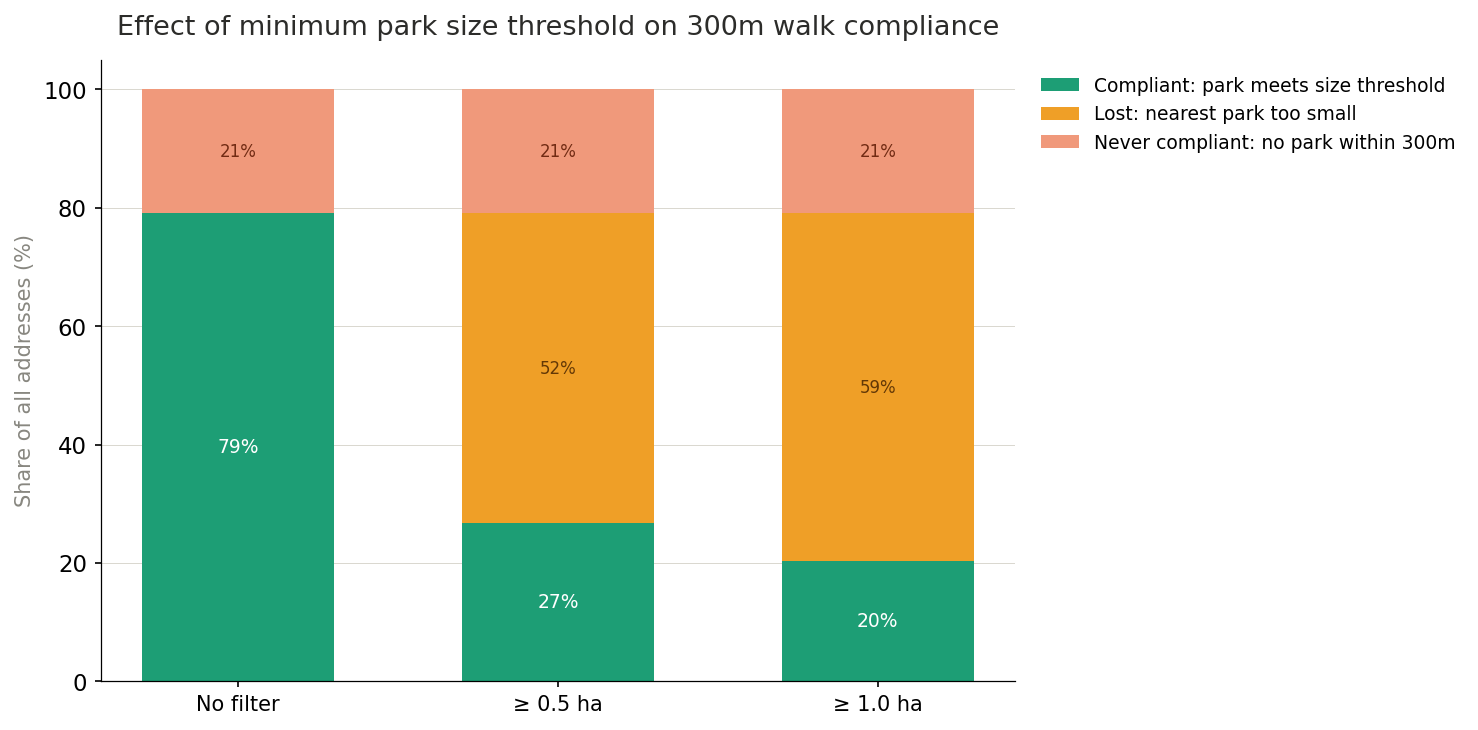

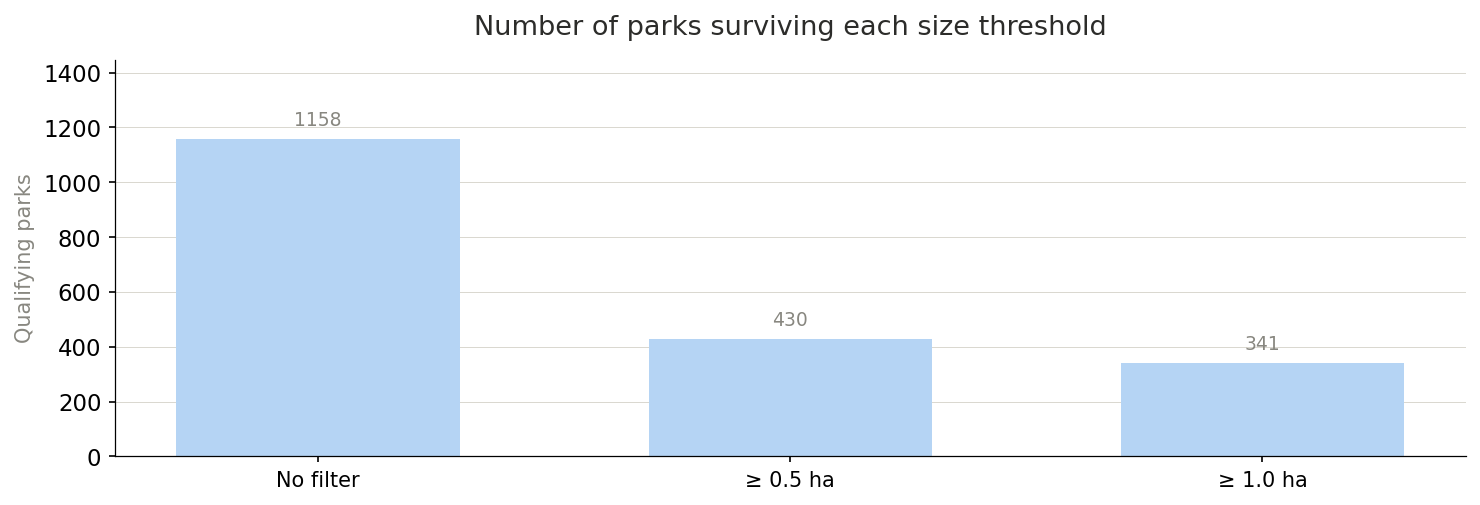

In [57]:
x       = size_df.index.to_numpy()
width   = 0.6
xlabels = ["No filter", "≥ 0.5 ha", "≥ 1.0 ha"]
#Stacked compliance bars
fig, ax_top = plt.subplots(figsize=(10, 5))

b1 = ax_top.bar(x, size_df.c_pct, width, color=TEAL,  label="Compliant: park meets size threshold", zorder=2)
b2 = ax_top.bar(x, size_df.l_pct, width, bottom=size_df.c_pct, color=AMBER, label="Lost: nearest park too small", zorder=2)
b3 = ax_top.bar(x, size_df.n_pct, width, bottom=size_df.c_pct + size_df.l_pct, color=CORAL, label="Never compliant: no park within 300m", zorder=2)

for i, row in size_df.iterrows():
    if row.c_pct > 5:
        ax_top.text(i, row.c_pct / 2, f"{row.c_pct:.0f}%",
            ha="center", va="center", fontsize=9, color="white", fontweight="500")
    if row.l_pct > 3:
        ax_top.text(i, row.c_pct + row.l_pct / 2, f"{row.l_pct:.0f}%",
            ha="center", va="center", fontsize=8, color="#633806")
    if row.n_pct > 3:
        ax_top.text(i, row.c_pct + row.l_pct + row.n_pct / 2, f"{row.n_pct:.0f}%",
            ha="center", va="center", fontsize=8, color="#712B13")
ax_top.set_xticks(x)
ax_top.set_xticklabels(xlabels, fontsize=10)
ax_top.set_ylabel("Share of all addresses (%)", fontsize=10, color=SGRAY)
ax_top.set_ylim(0, 105)
ax_top.set_title("Effect of minimum park size threshold on 300m walk compliance",
    fontsize=13, fontweight="500", pad=12, color=TEXT)
ax_top.grid(axis="y", linewidth=0.4, color=LGRAY, zorder=0)
ax_top.legend(fontsize=9, frameon=False, loc="upper left",
    bbox_to_anchor=(1.01, 1.0))

plt.tight_layout()
plt.savefig("fig/fig2b_300m_by_parksize.png", bbox_inches="tight", dpi=150)
plt.show()

# ── Figure 2b: Qualifying parks ──
fig, ax_bot = plt.subplots(figsize=(10, 3.5))

ax_bot.bar(x, size_df.parks, width, color="#B5D4F4", zorder=2)
for i, row in size_df.iterrows():
    ax_bot.text(i, row.parks + size_df.parks.max() * 0.03,
        str(int(row.parks)), ha="center", va="bottom", fontsize=9, color=SGRAY)

ax_bot.set_xticks(x)
ax_bot.set_xticklabels(xlabels, fontsize=10)
ax_bot.set_ylabel("Qualifying parks", fontsize=10, color=SGRAY)
ax_bot.set_title("Number of parks surviving each size threshold",
    fontsize=13, fontweight="500", color=TEXT, pad=12)
ax_bot.set_ylim(0, size_df.parks.max() * 1.25)
ax_bot.grid(axis="y", linewidth=0.4, color=LGRAY, zorder=0)

plt.tight_layout()
plt.savefig("fig/fig03a_walkability_compliance_by_park_size.png", bbox_inches="tight", dpi=150)
plt.show()

## Fig 3 - Euclidean vs. walk compliance by threshold 
- Note: Euclidean is computed only for matched rows (entrance coords available).
- For unmatched rows, walk_dist_m is NaN → treated as non-compliant at all thresholds, which is correct.

## % of parks in: euclidean distance vs. walking distance

In [61]:
w = 0.35

import numpy as np

# Define your distance thresholds (matching your plot x-axis labels)
dist_thresholds = [100, 200, 300, 400, 500]  # in meters

# Calculate walk_pct_real and euclid_pct_real for EACH threshold
walk_pct_real = []
euclid_pct_real = []
x = []

for threshold in dist_thresholds:
    # Walking distance compliance
    walk_compliant = results[results['walk_dist_m'] <= threshold]
    walk_pct = (len(walk_compliant) / len(results)) * 100
    walk_pct_real.append(walk_pct)
    
    # Euclidean distance compliance (only for matched entries with entrance coords)
    euclid_compliant = matched[matched['euclid_dist_m'] <= threshold]
    euclid_pct = (len(euclid_compliant) / len(matched)) * 100
    euclid_pct_real.append(euclid_pct)
    
    x.append(dist_thresholds.index(threshold))  # or just use range(len(dist_thresholds))

# Convert to numpy arrays for easier plotting
walk_pct_real = np.array(walk_pct_real)
euclid_pct_real = np.array(euclid_pct_real)
x = np.arange(len(dist_thresholds))

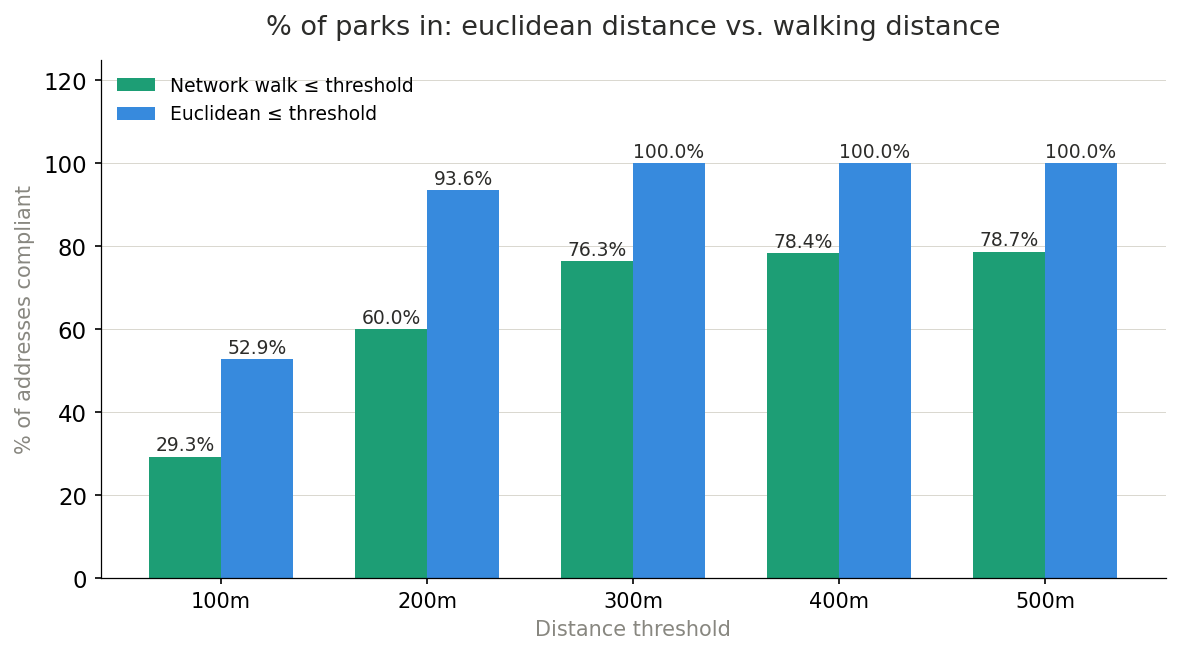

In [62]:

fig, ax = plt.subplots(figsize=(8, 4.5))

# Grouped bars, no secondary axis
b1 = ax.bar(x - w/2, walk_pct_real,   width=w, color=TEAL, label="Network walk ≤ threshold",  zorder=2, linewidth=0)
b2 = ax.bar(x + w/2, euclid_pct_real, width=w, color=BLUE, label="Euclidean ≤ threshold", zorder=2, linewidth=0)

# Value labels above bars
for bars in (b1, b2):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.4,
            f"{bar.get_height():.1f}%", ha="center", va="bottom", fontsize=9, color=TEXT)



ax.set_xticks(x)
ax.set_xticklabels([f"{t}m" for t in dist_thresholds], fontsize=10)
ax.set_ylabel("% of addresses compliant", fontsize=10, color=SGRAY)
ax.set_xlabel("Distance threshold", fontsize=10, color=SGRAY)
ax.set_title("% of parks in: euclidean distance vs. walking distance",
    fontsize=13, fontweight="500", pad=12, color=TEXT)
ax.set_ylim(0, max(euclid_pct_real) * 1.25)
ax.grid(axis="y", linewidth=0.4, color=LGRAY, zorder=0)

# clean single legend
ax.legend(handles=[b1, b2], fontsize=9, frameon=False,
    loc="upper left")

plt.tight_layout()
plt.savefig("fig/fig3_euclid_vs_walk.png", bbox_inches="tight", dpi=150)
plt.show()

## Fig 4  - Access gap map = address scatter coloured by 300m compliance

- Each dot = one civic address, plotted at its lon/lat.
- Teal  = within 300m walk of a park
- Coral = outside 300m (the access gap)
- Outside dots are drawn first so inside dots render on top where they overlap.

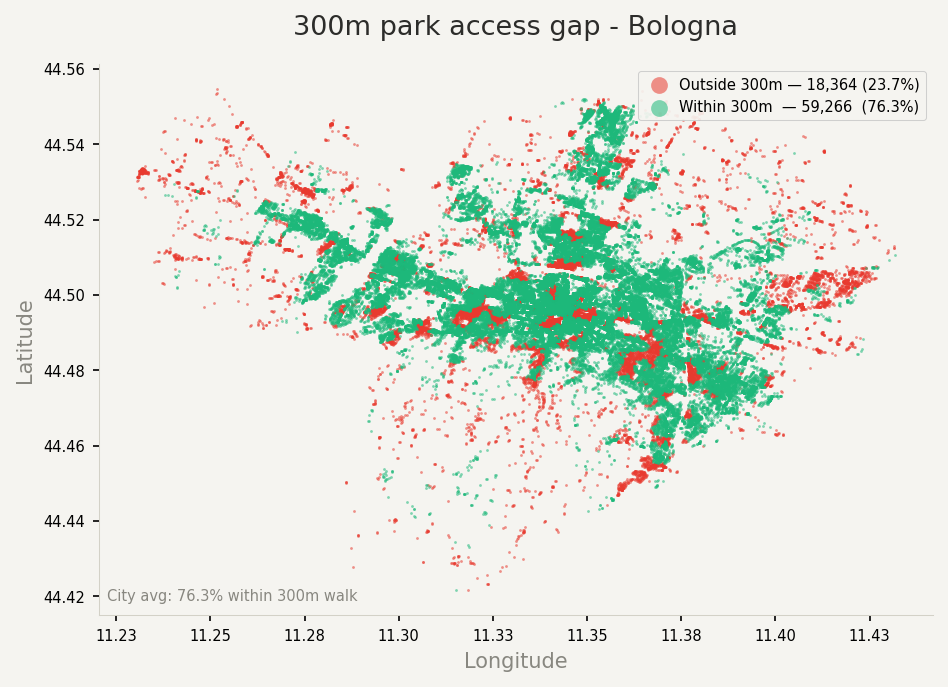

In [63]:
# Brighter colours for dot map
DOT_OUT = "#E83A2F"   # vivid red for outside (the problem)
DOT_IN  = "#1DB87A"   # vivid green for inside (the good)

inside  = results[results["within_300m"]]
outside = results[~results["within_300m"]]

lon_range = results["longitude"].max() - results["longitude"].min()
lat_range = results["latitude"].max()  - results["latitude"].min()
lat_mid   = results["latitude"].mean()
aspect    = lon_range / (lat_range * np.cos(np.radians(lat_mid)))
fig_w, fig_h = 10, 10 / aspect

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
fig.patch.set_facecolor("#F5F4F0")
ax.set_facecolor("#F5F4F0")

# Draw outside first (red), inside on top (green)
ax.scatter(outside["longitude"], outside["latitude"],
    s=1.8, color=DOT_OUT, alpha=0.55, linewidths=0,
    label=f"Outside 300m — {len(outside):,} ({len(outside)/total*100:.1f}%)",
    rasterized=True, zorder=2)
ax.scatter(inside["longitude"], inside["latitude"],
    s=1.8, color=DOT_IN,  alpha=0.55, linewidths=0,
    label=f"Within 300m  — {len(inside):,}  ({len(inside)/total*100:.1f}%)",
    rasterized=True, zorder=3)

ax.set_aspect("equal")
ax.set_xlabel("Longitude", fontsize=10, color=SGRAY)
ax.set_ylabel("Latitude",  fontsize=10, color=SGRAY)
ax.set_title("300m park access gap - Bologna",
    fontsize=13, fontweight="500", pad=14, color=TEXT)
ax.xaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))
ax.yaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))
ax.tick_params(labelsize=7)
for spine in ax.spines.values():
    spine.set_edgecolor(LGRAY)
    spine.set_linewidth(0.5)

# Legend upper right, slightly inset
legend = ax.legend(
    fontsize=7, frameon=True, framealpha=0.92, loc="upper right",
    markerscale=6, handletextpad=0.4,
)
legend.get_frame().set_linewidth(0.5)
legend.get_frame().set_facecolor("#F5F4F0")

ax.text(0.01, 0.02, f"City avg: {avg:.1f}% within 300m walk",
    transform=ax.transAxes, fontsize=7, color=SGRAY, ha="left", va="bottom")

plt.tight_layout()
plt.savefig("fig/fig4_access_gap_map.png", dpi=200, bbox_inches="tight")
plt.show()

# Area statistiche Bologna - compliance with 300m rule

In [ ]:
area_statistiche = gpd.read_file('data/300m/bologna_aree_statistiche.geojson')


In [ ]:
results['within_300m'] = results['within_300m'].fillna(False).astype(bool)

# Build a GeoDataFrame from the results points
results_gdf = gpd.GeoDataFrame(
    results,
    geometry=gpd.points_from_xy(results['longitude'], results['latitude']),
    crs='EPSG:4326'
)

# Ensure same CRS
area_statistiche = area_statistiche.to_crs('EPSG:4326')

# Spatial join: assign each point to its containing statistical area
joined = gpd.sjoin(
    results_gdf,
    area_statistiche[['area_statistica', 'geometry']],
    how='left',
    predicate='within'
)

# Aggregate per area  ← 'area_statistica' not 'area_statistiche'
stats = joined.groupby('area_statistica').agg(
    total_points=('within_300m', 'count'),
    access_points=('within_300m', 'sum')
).reset_index()
stats['access_pct'] = (stats['access_points'] / stats['total_points']) * 100

print(stats['access_pct'].describe())  # should show variance now
print(f"Areas covered: {len(stats)} / {len(area_statistiche)}")

count     90.000000
mean      69.233665
std       27.650394
min        0.000000
25%       55.125433
50%       80.677978
75%       89.393623
max      100.000000
Name: access_pct, dtype: float64
Areas covered: 90 / 90


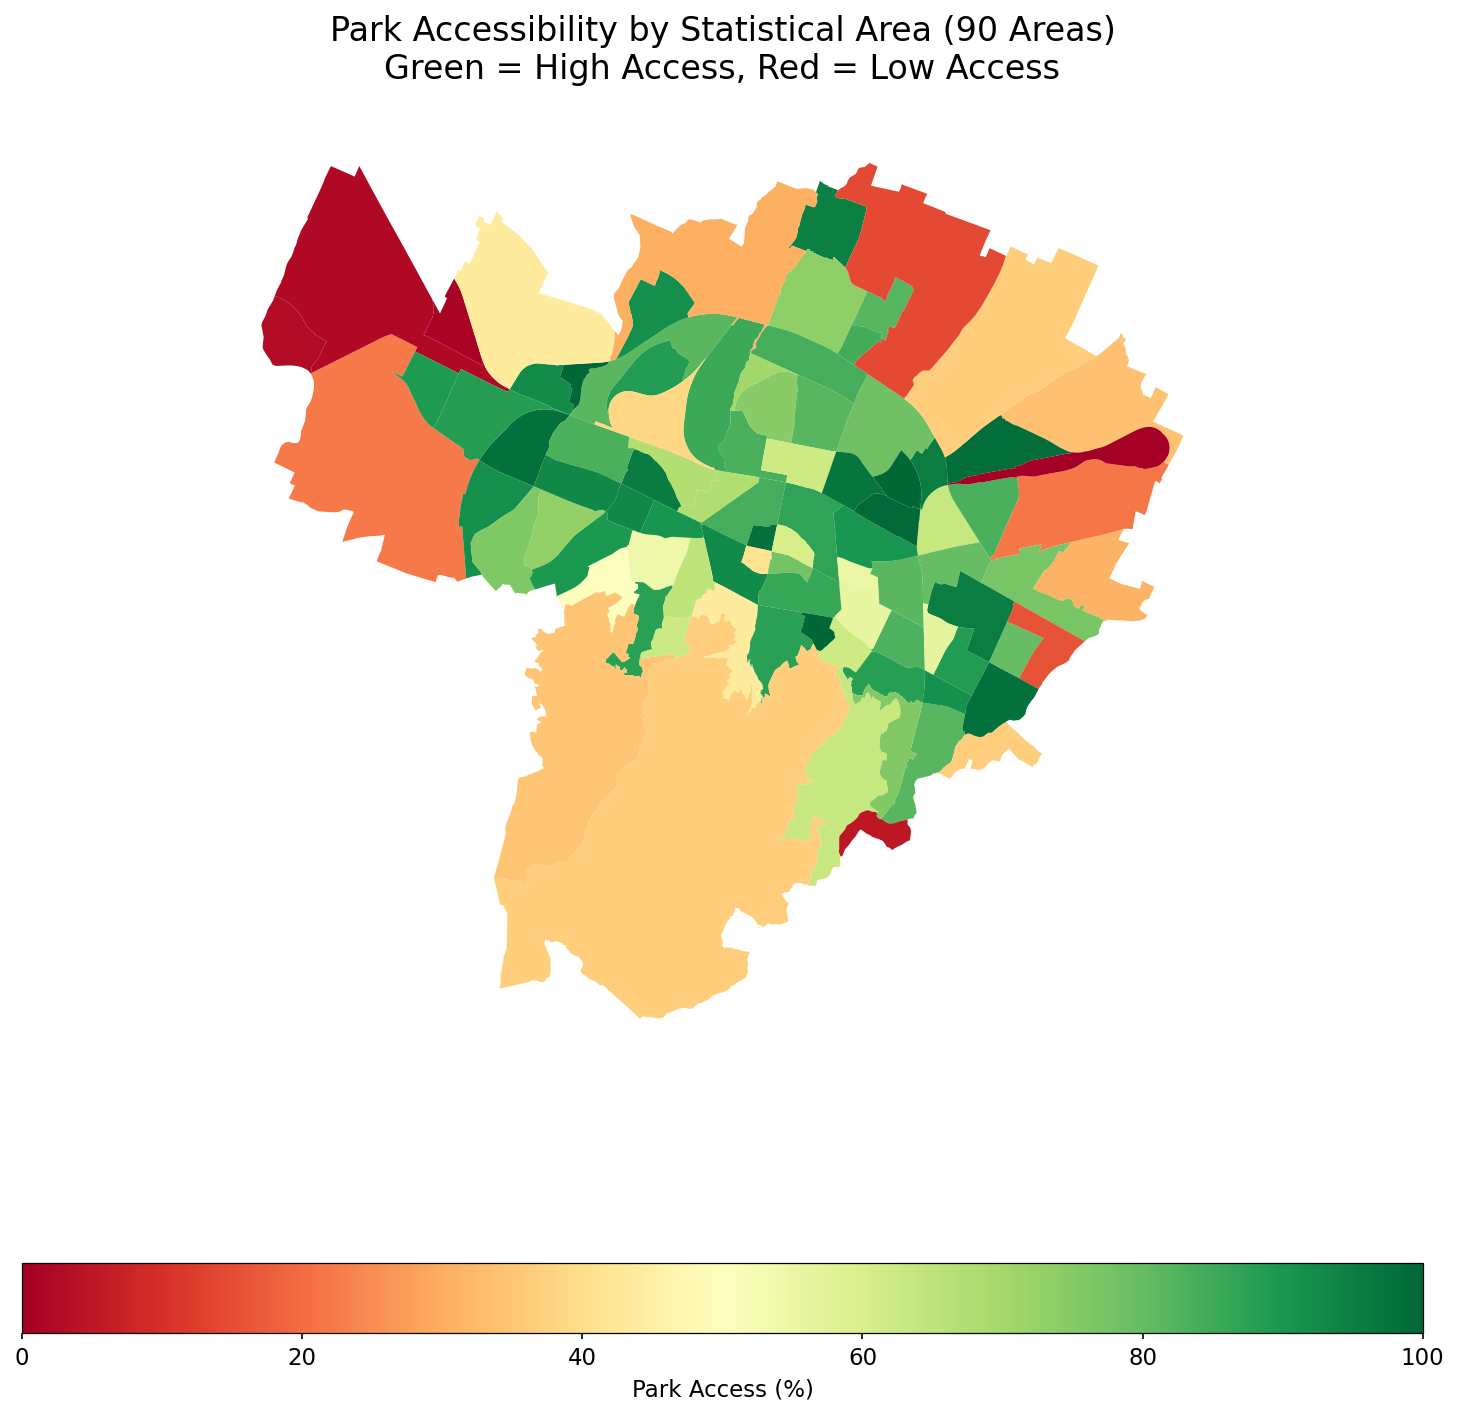

In [123]:

# 5. Merge stats back to geometry
gdf_plot = area_statistiche.merge(
    stats[['area_statistica', 'access_pct']], 
    on='area_statistica', 
    how='left'
)
gdf_plot['access_pct'] = gdf_plot['access_pct'].fillna(0)

# 6. Plot
fig, ax = plt.subplots(figsize=(12, 10))
gdf_plot.plot(
    column='access_pct',
    cmap='RdYlGn',
    linewidth=0.5,
    ax=ax,
    legend=True,
    vmin=0,
    vmax=100,
    legend_kwds={'label': "Park Access (%)", 'shrink': 0.8, 'orientation': "horizontal"}
)
ax.set_title(
    "Park Accessibility by Statistical Area (90 Areas)\nGreen = High Access, Red = Low Access",
    fontsize=16, pad=20
)
ax.axis('off')
plt.tight_layout()
plt.savefig("fig/fig10_park_access_heatmap.png", dpi=300, bbox_inches='tight')
plt.show()